# PD04 · Limpieza e integración territorial

Continuación de PD01–PD03 basada en las clases del 9 y 10 de octubre de 2026. Tiempo orientativo: 270 minutos, con el entorno y los datos preparados.

Copia esta plantilla a `soluciones/` conservando su nombre. Escribe allí el código y las interpretaciones. Las celdas iniciales muestran las lecturas; las actividades quedan a tu cargo. Antes de entregar, reinicia el kernel y ejecuta todas las celdas en orden.

Utiliza directamente las API de pandas, GeoPandas y, en PD05, Polars. Mantén visibles las conversiones, máscaras, agrupaciones, uniones y exportaciones. No uses `talleres.py`, `pqrs_talleres.py`, comandos de shell ni funciones que resuelvan varias etapas sin mostrar su implementación. Un bucle de medición es válido si su cuerpo contiene las operaciones que estás midiendo. No instales paquetes desde el notebook.

[Índice](../ejercicios/README.md) · [Pandas](../docs/manual-pandas.md) · [Polars](../docs/manual-polars.md) · [GeoPandas](../docs/manual-geopandas.md)

## Ubicación de trabajo

Abre Jupyter desde la raíz del repositorio con el entorno del curso activo. Cambia `REPO` por la ruta real de tu copia. Las rutas son explícitas y funcionan tanto desde `ejercicios/` como desde `soluciones/`. Si falta un archivo, revisa su ubicación; no sustituyas silenciosamente la entrada por otro dataset.

## Pregunta y entradas

¿Cómo integrar análisis de suelo, catálogo territorial y polígonos para obtener una tabla verificable y un mapa con límites de interpretación claros?

| Fuente | Lectura directa | Uso |
|---|---|---|
| `agrosavia.csv` | `pd.read_csv` | Análisis, fechas y medidas con tipos y marcadores variados. |
| `divipola.csv` | `pd.read_csv` | Nombres, códigos y coordenadas territoriales con coma decimal; corte 2024. |
| `dane_municipios.zip` | `gpd.read_file` | Polígonos municipales MGN 2025 y código `mpio_cdpmp`. |
| `igac_capacidad.json` | `gpd.read_file` | Muestra GeoJSON de cinco polígonos de capacidad de uso. |

Primero integra las dos tablas con pandas. Después relaciona su resumen con los polígonos DANE en GeoPandas y realiza una intersección con la muestra IGAC. Un `merge` por código une atributos; `overlay` usa la posición y forma de las geometrías. Explica esa diferencia en tus resultados.

Las coordenadas de DIVIPOLA no son ubicaciones de muestras de suelo. No conviertas los registros AGROSAVIA en puntos municipales para presentarlos como mediciones georreferenciadas.

Prepara el ZIP siguiendo la [descarga manual DANE](../docs/entorno.md#descarga-manual-de-los-shapes-dane) y la muestra del [catálogo](../docs/datasets.md). Conserva juntos los componentes del Shapefile dentro del ZIP. Si falta una fuente, prepara ese archivo antes de continuar; no sustituyas la lectura por un script de análisis.

`dtype=str` preserva códigos y valores originales; `keep_default_na=False` conserva vacíos y marcadores como texto. Revisa las opciones de cada lectura.

In [23]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

REPO = "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate"
RAW = REPO + "/kit/data/raw"
OUT = REPO + "/kit/salidas/soluciones/PD04"
os.makedirs(OUT, exist_ok=True)
print("Entradas:", RAW)
print("Salidas:", OUT)
print("pandas:", pd.__version__, "GeoPandas:", gpd.__version__)

Entradas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/raw
Salidas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04
pandas: 2.2.3 GeoPandas: 1.2.0


In [3]:
suelo = pd.read_csv(
    RAW + "/agrosavia.csv",
    sep=",",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)
display(suelo.head())
print(suelo.shape)

,Secuencial,Fecha de Análisis,Departamento,Municipio,Cultivo,Estado,Tiempo de establecimiento,Topografia,Drenaje,Riego,...,Conductividad electrica,Hierro disponible olsen,Cobre disponible,Manganeso disponible Olsen,Zinc disponible Olsen,Boro disponible,Hierro disponible doble acido,Cobre disponible doble acido,Manganeso disponible doble acido,Zinc disponible doble acido
0,1,7/01/2014,NARIÑO,SAN ANDRÉS DE TUMACO,No Indica,No indica,No indica,No indica,No indica,No indica,...,0.133,66.39,1.700,1.700,1.5,0.187,ND,ND,ND,ND
1,2,21/08/2014,HUILA,SANTA MARÍA,Granadilla,Establecido,De 1 a 5 años,Pendiente,Buen drenaje,No Tiene,...,2.749,250.9,3.7,29.4,28.70,2.084,ND,ND,ND,ND
2,3,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Pendiente,Mal drenaje,No Tiene,...,0.328,390,11.10,8.299,5,0.085,ND,ND,ND,ND
3,4,22/08/2014,ANTIOQUIA,LIBORINA,Maracuyá,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,0.171,200,4.2,4.699,1,0.229,ND,ND,ND,ND
4,5,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,0.323,117.9,3.8,4.600,0.700,0.139,ND,ND,ND,ND


(92738, 32)


In [4]:
territorio = pd.read_csv(
    RAW + "/divipola.csv",
    sep=",",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)
display(territorio.head())
print(territorio.shape)

,Código Departamento,Nombre Departamento,Código Municipio,Nombre Municipio,Tipo: Municipio / Isla / Área no municipalizada,longitud,Latitud
0,05,ANTIOQUIA,05001,MEDELLÍN,Municipio,"-75,581775","6,246631"
1,05,ANTIOQUIA,05002,ABEJORRAL,Municipio,"-75,428739","5,789315"
2,05,ANTIOQUIA,05004,ABRIAQUÍ,Municipio,"-76,064304","6,632282"
3,05,ANTIOQUIA,05021,ALEJANDRÍA,Municipio,"-75,141346","6,376061"
4,05,ANTIOQUIA,05030,AMAGÁ,Municipio,"-75,702188","6,038708"


(1122, 7)


## 1. Diagnóstico y contrato · 20 minutos

Muestra dimensiones, columnas y tipos de ambas tablas. Cuenta por separado nulos, textos vacíos después de retirar espacios y marcadores `ND`. Examina fecha, pH, nombres territoriales y coordenadas.

Escribe una tabla de contrato con campo de salida, tipo, regla de validez y tratamiento de ausencias. Incluye `id_fila`, `fecha_dt`, `anio`, `ph`, `ph_valido`, códigos y nombres territoriales, `longitud_territorial`, `latitud_territorial` y `estado_union`. Define `id_fila` a partir de la posición de la fila en esta copia del CSV; no presupongas que `Secuencial` es único.

**Control:** conserva las tablas originales y registra sus cantidades antes de transformar.

In [6]:
# Desarrollo
filas_suelo = suelo.shape[0]
filas_territorio = territorio.shape[0]

print("suelo:", suelo.shape)
print(list(suelo.columns))
print(suelo.dtypes.value_counts())

print("territorio:", territorio.shape)
print(list(territorio.columns))
print(territorio.dtypes)

diag = {}
for nombre, tabla in [("suelo", suelo), ("territorio", territorio)]:
    limpio = tabla.apply(lambda col: col.str.strip())
    diag[nombre] = pd.DataFrame({
        "nulos": tabla.isna().sum(),
        "vacios": limpio.eq("").sum(),
        "nd": limpio.apply(lambda col: col.str.upper().eq("ND")).sum(),
    })
    print(nombre)
    display(diag[nombre])

fecha_tmp = pd.to_datetime(suelo["Fecha de Análisis"].str.strip(), format="%d/%m/%Y", errors="coerce")
print("Fechas no interpretables:", fecha_tmp.isna().sum(), "| rango:", fecha_tmp.min(), fecha_tmp.max())

ph_texto = suelo["pH agua:suelo"].str.strip()
ph_tmp = pd.to_numeric(ph_texto.str.replace(",", ".", regex=False), errors="coerce")
ph_fallido = ph_tmp.isna() & ph_texto.ne("")
print("pH fallidos:", ph_fallido.sum())
display(ph_texto[ph_fallido].value_counts().head())
print(ph_tmp.describe())

dep_suelo = set(suelo["Departamento"].str.strip().str.upper())
dep_terr = set(territorio["Nombre Departamento"].str.strip().str.upper())
print("Departamentos en suelo sin par en territorio:", sorted(dep_suelo - dep_terr))

mun_suelo = set(suelo["Municipio"].str.strip().str.upper())
mun_terr = set(territorio["Nombre Municipio"].str.strip().str.upper())
print("Municipios en suelo sin par en territorio:", len(mun_suelo - mun_terr))
print(sorted(mun_suelo - mun_terr)[:10])

lon = pd.to_numeric(territorio["longitud"].str.strip().str.replace(",", ".", regex=False), errors="coerce")
lat = pd.to_numeric(territorio["Latitud"].str.strip().str.replace(",", ".", regex=False), errors="coerce")
print("Longitud sin número:", lon.isna().sum(), "| Latitud sin número:", lat.isna().sum())
print(lon.describe())
print(lat.describe())

fuera = ~(lon.between(-82, -66) & lat.between(-4.5, 13.5))
print("Coordenadas fuera del rango aproximado de Colombia:", fuera.sum())

print("Secuencial único:", suelo["Secuencial"].is_unique, "| duplicados:", suelo["Secuencial"].duplicated().sum())
# Construye el diagnóstico y escribe el contrato en una celda Markdown.

suelo: (92738, 32)
['Secuencial', 'Fecha de Análisis', 'Departamento', 'Municipio', 'Cultivo', 'Estado', 'Tiempo de establecimiento', 'Topografia', 'Drenaje', 'Riego', 'Fertilizantes aplicados', 'pH agua:suelo', 'Materia organica', 'Fósforo Bray II', 'Azufre Fosfato monocalcico', 'Acidez Intercambiable', 'Aluminio intercambiable', 'Calcio intercambiable', 'Magnesio intercambiable', 'Potasio intercambiable', 'Sodio intercambiable', 'capacidad de intercambio cationico', 'Conductividad electrica', 'Hierro disponible olsen', 'Cobre disponible', 'Manganeso disponible Olsen', 'Zinc disponible Olsen', 'Boro disponible', 'Hierro disponible doble acido', 'Cobre disponible doble acido', 'Manganeso disponible doble acido', 'Zinc disponible doble \xa0acido']
object    32
Name: count, dtype: int64
territorio: (1122, 7)
['Código Departamento', 'Nombre Departamento', 'Código Municipio', 'Nombre Municipio', 'Tipo: Municipio / Isla / Área no municipalizada', 'longitud', 'Latitud']
Código Departamento  

,nulos,vacios,nd
Secuencial,0,0,0
Fecha de Análisis,0,0,0
Departamento,0,0,0
Municipio,0,2,0
Cultivo,0,0,0
Estado,0,0,0
Tiempo de establecimiento,0,0,0
Topografia,0,0,0
Drenaje,0,0,0
Riego,0,0,0


territorio


,nulos,vacios,nd
Código Departamento,0,0,0
Nombre Departamento,0,0,0
Código Municipio,0,0,0
Nombre Municipio,0,0,0
Tipo: Municipio / Isla / Área no municipalizada,0,0,0
longitud,0,0,0
Latitud,0,0,0


Fechas no interpretables: 0 | rango: 2014-01-07 00:00:00 2025-09-05 00:00:00
pH fallidos: 11


pH agua:suelo
<3.80     6
>10.00    4
4..01     1
Name: count, dtype: int64

count    92727.000000
mean         5.708232
std          1.019957
min          3.190000
25%          4.960000
50%          5.470000
75%          6.260000
max         10.570000
Name: pH agua:suelo, dtype: float64
Departamentos en suelo sin par en territorio: []
Municipios en suelo sin par en territorio: 24
['', 'ANCUYÁ', 'ARMERO GUAYABAL', 'BARRANCO MINAS', 'BELÉN DE BAJIRÁ', 'BOGOTÁ,  D.C.', 'BORRAR', 'CALI', 'COLOSO', 'CUASPUD']
Longitud sin número: 0 | Latitud sin número: 0
count    1122.000000
mean      -74.651854
std         1.675067
min       -81.707181
25%       -75.767018
50%       -74.767318
75%       -73.449635
max       -66.963692
Name: longitud, dtype: float64
count    1122.000000
mean        5.614861
std         2.646144
min        -4.198950
25%         4.262183
50%         5.529295
75%         7.025522
max        13.373185
Name: Latitud, dtype: float64
Coordenadas fuera del rango aproximado de Colombia: 0
Secuencial único: True | duplicados: 0


**Contrato de salida**

`id_fila` se define por la posición de la fila en esta copia del CSV. No se usa `Secuencial`.

| Campo de salida | Tipo | Regla de validez | Tratamiento de ausencias |
|---|---|---|---|
| `id_fila` | Int64 | Entero único, igual a la posición de la fila en `suelo` | No admite ausencias |
| `fecha_dt` | datetime64 | Formato `%d/%m/%Y` | Fecha no interpretable queda `NaT`; se cuenta aparte de la vacía |
| `anio` | Int64 | Año extraído de `fecha_dt` | `<NA>` si `fecha_dt` es `NaT` |
| `ph` | float64 | Número con punto decimal tras `.str.replace(",", ".")` | Vacío, `ND` o texto no numérico queda `NaN`; nunca se reemplaza por 0 |
| `ph_valido` | bool | `True` si `ph` no es `NaN` y está en [0, 14] | `False` cuando `ph` es `NaN` |
| `codigo_departamento` | texto | Dos cifras (`.str.fullmatch(r"[0-9]{2}")`) | Queda vacío si la fila no encuentra pareja |
| `codigo_municipio` | texto | Cinco cifras, único en `territorio` | Queda vacío si la fila no encuentra pareja |
| `departamento`, `municipio` | texto | Nombre de DIVIPOLA tras normalizar espacios y mayúsculas | Vacío si no hay unión |
| `longitud_territorial`, `latitud_territorial` | float64 | Número con punto decimal, dentro del rango de Colombia | `NaN` si no hay unión o no se convierte; no se rellena |
| `estado_union` | texto | `both` o `left_only` según el `indicator` del merge | Toda fila tiene un estado |

Las coordenadas son del municipio en DIVIPOLA, no de la ubicación de la muestra de suelo.

In [7]:
assert suelo.shape[0] == filas_suelo
assert territorio.shape[0] == filas_territorio == 1122
print("Tablas originales:", filas_suelo, "y", filas_territorio)

Tablas originales: 92738 y 1122


**Interpretación:**

Se registraron las cantidades originales antes de transformar: `suelo` tiene 92.738 filas y 32 columnas, y `territorio` tiene 1.122 filas y 7 columnas. Ambas se leyeron como texto, por eso no hay nulos de pandas; los vacíos y los marcadores `ND` se cuentan aparte.

**Controles obtenidos.**
- En `suelo`, `Municipio` tiene 2 textos vacíos y `Materia organica` tiene 2 marcadores `ND`.
- Las 92.738 fechas se interpretan con `%d/%m/%Y`.
- En el pH, 11 textos no se convierten: 6 valores `<3.80` y 4 valores `>10.00` y 1 error de digitación (`4..01`). Quedarán como `NaN`, sin reemplazar por cero.
- Los departamentos de `suelo` tienen pareja en `territorio`, pero 24 municipios no la tienen. Hay vacíos, nombres con formato distinto (`BOGOTÁ,  D.C.`) y valores como `BORRAR`.
- Las 1.122 coordenadas de DIVIPOLA se convierten sin fallos y caen dentro del rango aproximado de Colombia.
- `Secuencial` es único en esta copia, pero `id_fila` se define por posición para no depender de ese supuesto.

**Límites.**
- Los conteos solo detectan lo que no se convierte o no coincide. Un pH numérico plausible pero erróneo no queda marcado.
- La unión por nombre normalizado depende de la escritura. Los 24 municipios sin pareja quedarán como `left_only` en `estado_union`, sin eliminarse, y no se sabe todavía cuáles son errores de escritura y cuáles no existen en DIVIPOLA.
- La verificación de coordenadas usa un rango aproximado. Confirma que están en Colombia, no que cada punto corresponda a su municipio.
- Las coordenadas son del municipio en DIVIPOLA, no de la ubicación de la muestra de suelo.

## 2. Conversión de medidas, fechas y coordenadas · 30 minutos

Crea columnas nuevas. Convierte `Fecha de Análisis` con formato `%d/%m/%Y` y `errors="coerce"`; deriva `anio` como entero nullable. Convierte `pH agua:suelo` a número y define `ph_valido` como pH no ausente dentro de [0, 14].

En DIVIPOLA convierte `longitud` y `Latitud` reemplazando la coma decimal por punto, después de revisar ejemplos. No apliques esa regla a todos los campos. Usa `pd.to_numeric(..., errors="coerce")`. Conserva valores originales y distingue ausencias de textos no vacíos que fallaron al convertir.

**Control:** muestra conteos y hasta cinco ejemplos por fallo. Revisa longitud en [−180, 180] y latitud en [−90, 90]. Un rango válido no demuestra que la ubicación sea correcta. No sustituyas ausencias por cero.

In [8]:
# Desarrollo
suelo["id_fila"] = pd.Series(range(len(suelo)), index=suelo.index).astype("Int64")

fecha_texto = suelo["Fecha de Análisis"].str.strip()
suelo["fecha_dt"] = pd.to_datetime(fecha_texto, format="%d/%m/%Y", errors="coerce")
suelo["anio"] = suelo["fecha_dt"].dt.year.astype("Int64")

fecha_vacia = fecha_texto.eq("")
fecha_fallida = suelo["fecha_dt"].isna() & ~fecha_vacia
print("Fechas vacías:", fecha_vacia.sum(), "| fallidas:", fecha_fallida.sum())
display(suelo.loc[fecha_fallida, ["id_fila", "Fecha de Análisis"]].head(5))

ph_texto = suelo["pH agua:suelo"].str.strip()
suelo["ph"] = pd.to_numeric(ph_texto.str.replace(",", ".", regex=False), errors="coerce")
suelo["ph_valido"] = suelo["ph"].between(0, 14)

ph_vacio = ph_texto.eq("")
ph_fallido = suelo["ph"].isna() & ~ph_vacio
print("pH vacíos:", ph_vacio.sum(), "| fallidos:", ph_fallido.sum())
print("ph_valido True:", suelo["ph_valido"].sum(), "| False:", (~suelo["ph_valido"]).sum())
display(suelo.loc[ph_fallido, ["id_fila", "pH agua:suelo"]].head(5))

display(territorio[["Nombre Municipio", "longitud", "Latitud"]].head())
print("Longitudes con coma:", territorio["longitud"].str.contains(",", regex=False).sum())
print("Latitudes con coma:", territorio["Latitud"].str.contains(",", regex=False).sum())

lon_texto = territorio["longitud"].str.strip()
lat_texto = territorio["Latitud"].str.strip()

territorio["longitud_territorial"] = pd.to_numeric(lon_texto.str.replace(",", ".", regex=False), errors="coerce")
territorio["latitud_territorial"] = pd.to_numeric(lat_texto.str.replace(",", ".", regex=False), errors="coerce")

lon_fallida = territorio["longitud_territorial"].isna() & lon_texto.ne("")
lat_fallida = territorio["latitud_territorial"].isna() & lat_texto.ne("")
print("Longitud vacía:", lon_texto.eq("").sum(), "| fallida:", lon_fallida.sum())
print("Latitud vacía:", lat_texto.eq("").sum(), "| fallida:", lat_fallida.sum())
display(territorio.loc[lon_fallida | lat_fallida, ["Nombre Municipio", "longitud", "Latitud"]].head(5))

lon_fuera = territorio["longitud_territorial"].notna() & ~territorio["longitud_territorial"].between(-180, 180)
lat_fuera = territorio["latitud_territorial"].notna() & ~territorio["latitud_territorial"].between(-90, 90)
print("Longitud fuera de [-180, 180]:", lon_fuera.sum())
print("Latitud fuera de [-90, 90]:", lat_fuera.sum())

assert len(suelo) == filas_suelo
assert len(territorio) == filas_territorio
assert suelo["id_fila"].is_unique
assert suelo["ph"].isna().sum() == ph_vacio.sum() + ph_fallido.sum()
assert suelo["fecha_dt"].isna().sum() == fecha_vacia.sum() + fecha_fallida.sum()
assert "Fecha de Análisis" in suelo.columns and "pH agua:suelo" in suelo.columns
assert "longitud" in territorio.columns and "Latitud" in territorio.columns

Fechas vacías: 0 | fallidas: 0


,id_fila,Fecha de Análisis


pH vacíos: 0 | fallidos: 11
ph_valido True: 92727 | False: 11


,id_fila,pH agua:suelo
7282,7282,4..01
46528,46528,>10.00
46530,46530,>10.00
52903,52903,<3.80
56330,56330,<3.80


,Nombre Municipio,longitud,Latitud
0,MEDELLÍN,"-75,581775","6,246631"
1,ABEJORRAL,"-75,428739","5,789315"
2,ABRIAQUÍ,"-76,064304","6,632282"
3,ALEJANDRÍA,"-75,141346","6,376061"
4,AMAGÁ,"-75,702188","6,038708"


Longitudes con coma: 1122
Latitudes con coma: 1122
Longitud vacía: 0 | fallida: 0
Latitud vacía: 0 | fallida: 0


,Nombre Municipio,longitud,Latitud


Longitud fuera de [-180, 180]: 0
Latitud fuera de [-90, 90]: 0


**Interpretación:**

Se crearon `id_fila`, `fecha_dt`, `anio`, `ph` y `ph_valido` en `suelo`, y `longitud_territorial` y `latitud_territorial` en `territorio`, conservando las columnas originales y todas las filas. `id_fila` se definió por la posición de la fila, sin depender de `Secuencial`.

**Controles obtenidos.**
- **Fechas:** 0 vacías y 0 fallidas con `%d/%m/%Y`, así que `fecha_dt` y `anio` no tienen ausencias.
- **pH:** 0 vacíos y **11 textos no vacíos que no se convirtieron**: `4..01` (error de digitación), `>10.00` y `<3.80`, quedan como `NaN`, sin reemplazar por cero. `ph_valido` es `True` en 92.727 filas y `False` en 11.
- **Coordenadas:** las 1.122 longitudes y latitudes de DIVIPOLA traían coma decimal. La regla de reemplazo se aplicó solo a esas dos columnas, no hubo vacías ni fallidas.

**Límites.**
- Un rango válido no demuestra que la ubicación sea correcta: una coordenada puede estar dentro de [−90, 90] y aun así no corresponder al municipio.
- `ph_valido` solo comprueba que el pH sea numérico y esté en [0, 14]. No detecta un valor plausible pero erróneo, ni distingue los censurados (`<3.80`, `>10.00`) de un error de digitación: todos quedan igual como no válidos.
- Las coordenadas son del municipio en DIVIPOLA, no de la ubicación de la muestra de suelo.

## 3. Normalización de nombres y claves · 30 minutos

Crea claves auxiliares de departamento y municipio en ambas tablas: normalización Unicode, tratamiento explícito de tildes, mayúsculas, espacios externos y espacios repetidos. Muestra cada operación con `.str`; conserva el texto original. Describe qué diferencias podrían perderse al normalizar.

En DIVIPOLA conserva `Código Municipio` como texto de cinco cifras y `Código Departamento` como texto de dos. Revisa unicidad de código y de la pareja de nombres normalizados. Detecta claves vacías y colisiones antes de unir.

**Control:** exporta las claves ambiguas. Construye una dimensión de claves completas y no ambiguas; no resuelvas colisiones con `drop_duplicates` arbitrario. Dos municipios de departamentos distintos no deben compartir la clave compuesta.

In [9]:
# Desarrollo
pares = [
    (territorio, "Nombre Departamento", "clave_depto"),
    (territorio, "Nombre Municipio", "clave_mpio"),
    (suelo, "Departamento", "clave_depto"),
    (suelo, "Municipio", "clave_mpio"),
]

for tabla, origen, destino in pares:
    t = tabla[origen]
    t = t.str.normalize("NFKD")
    t = t.str.encode("ascii", errors="ignore").str.decode("ascii")
    t = t.str.upper()
    t = t.str.strip()
    t = t.str.replace(r"\s+", " ", regex=True)
    tabla[destino] = t

display(suelo.loc[suelo["Municipio"].str.contains("BOGOT", case=False), ["Municipio", "clave_mpio"]].drop_duplicates())
display(territorio[["Nombre Municipio", "clave_mpio"]].head())

territorio["codigo_departamento"] = territorio["Código Departamento"].str.strip()
territorio["codigo_municipio"] = territorio["Código Municipio"].str.strip()
print("Dpto. con dos cifras:", territorio["codigo_departamento"].str.fullmatch(r"[0-9]{2}").sum())
print("Mpio. con cinco cifras:", territorio["codigo_municipio"].str.fullmatch(r"[0-9]{5}").sum())
print("Código municipal único:", territorio["codigo_municipio"].is_unique)
print("Prefijo coincide con dpto.:", (territorio["codigo_municipio"].str[:2] == territorio["codigo_departamento"]).all())

territorio["clave_compuesta"] = territorio["clave_depto"] + "|" + territorio["clave_mpio"]
clave_vacia = territorio["clave_depto"].eq("") | territorio["clave_mpio"].eq("")
colision = territorio["clave_compuesta"].duplicated(keep=False)
print("Claves vacías:", clave_vacia.sum())
print("Filas en colisión:", colision.sum())
print("Clave compuesta única:", territorio["clave_compuesta"].is_unique)
display(territorio.loc[colision, ["codigo_municipio", "Nombre Departamento", "Nombre Municipio", "clave_compuesta"]].sort_values("clave_compuesta"))

dep_codigos = territorio.groupby("clave_depto")["codigo_departamento"].nunique()
print("Nombres de dpto. con más de un código:", (dep_codigos > 1).sum())

# Normaliza nombres y separa claves territoriales ambiguas.
ambigua = clave_vacia | colision

claves_ambiguas = territorio.loc[ambigua, ["codigo_departamento", "codigo_municipio", "Nombre Departamento", "Nombre Municipio", "clave_compuesta"]]
ruta_amb = OUT + "/claves_ambiguas.csv"
claves_ambiguas.to_csv(ruta_amb, index=False)

dimension_claves = territorio.loc[~ambigua, ["codigo_departamento", "codigo_municipio", "Nombre Departamento", "Nombre Municipio", "clave_depto", "clave_mpio", "clave_compuesta", "longitud_territorial", "latitud_territorial"]].copy()

print("Ambiguas:", len(claves_ambiguas), "| Dimensión:", len(dimension_claves))
display(pd.read_csv(ruta_amb, dtype=str, keep_default_na=False))

print("suelo con clave_depto vacía:", suelo["clave_depto"].eq("").sum())
print("suelo con clave_mpio vacía:", suelo["clave_mpio"].eq("").sum())

assert len(dimension_claves) + len(claves_ambiguas) == len(territorio) == filas_territorio
assert dimension_claves["clave_compuesta"].is_unique
assert dimension_claves["clave_compuesta"].ne("").all()
assert len(suelo) == filas_suelo

,Municipio,clave_mpio
833,"BOGOTÁ, D.C.","BOGOTA, D.C."


,Nombre Municipio,clave_mpio
0,MEDELLÍN,MEDELLIN
1,ABEJORRAL,ABEJORRAL
2,ABRIAQUÍ,ABRIAQUI
3,ALEJANDRÍA,ALEJANDRIA
4,AMAGÁ,AMAGA


Dpto. con dos cifras: 1122
Mpio. con cinco cifras: 1122
Código municipal único: True
Prefijo coincide con dpto.: True
Claves vacías: 0
Filas en colisión: 0
Clave compuesta única: True


,codigo_municipio,Nombre Departamento,Nombre Municipio,clave_compuesta


Nombres de dpto. con más de un código: 0
Ambiguas: 0 | Dimensión: 1122


,codigo_departamento,codigo_municipio,Nombre Departamento,Nombre Municipio,clave_compuesta


suelo con clave_depto vacía: 0
suelo con clave_mpio vacía: 2


**Interpretación:**

Se crearon `clave_depto` y `clave_mpio` en `suelo` y `territorio` aplicando por separado normalización Unicode (`NFKD`), eliminación de tildes, mayúsculas, retiro de espacios externos y colapso de espacios repetidos. Los textos originales se conservaron.

**Controles obtenidos.**
- Los **1.122** códigos de DIVIPOLA se conservaron como texto: todos los departamentos tienen dos cifras, todos los municipios cinco, el código municipal es único y su prefijo coincide con el código departamental.
- No hay claves vacías ni colisiones: la clave compuesta (`departamento|municipio`) es única en las 1.122 filas, y ningún nombre de departamento tiene más de un código.
- `claves_ambiguas.csv` se exportó con **0 filas** y solo la cabecera. La dimensión `dimension_claves` conserva las **1.122** claves completas y no ambiguas, sin usar `drop_duplicates`.
- En `suelo`, `clave_depto` no tiene vacíos y `clave_mpio` tiene **2**, que corresponden a los textos vacíos de `Municipio`. No se corrigen; quedarán como `left_only` en la unión.

**Límites.**
- Al normalizar se pierden diferencias: la `Ñ` pasa a `N` y las tildes dejan de distinguir palabras. Dos nombres distintos que solo difieran en eso colisionarían. Aquí no ocurre en DIVIPOLA, pero la ausencia de colisiones se comprobó solo en esa tabla.
- Una clave única no garantiza que la unión sea correcta: los 24 municipios de `suelo` sin pareja (como `BORRAR` o nombres escritos de otra forma) seguirán sin coincidir, porque la normalización no corrige errores de escritura.
- La clave compuesta evita que dos municipios de departamentos distintos se confundan, pero depende de que el nombre del departamento esté bien escrito en `suelo`.

## 4. Integración y equivalencias justificadas · 40 minutos

Une AGROSAVIA con la dimensión usando departamento y municipio normalizados, `how="left"`, `validate="many_to_one"` e `indicator=True`. No permitas que claves incompletas coincidan entre sí. Conserva una fila por análisis y distingue coincidencia, clave incompleta, ambigüedad y falta de correspondencia.

Revisa hasta diez nombres sin correspondencia. Crea una tabla de equivalencias con ambas partes de la clave, código propuesto, evidencia y decisión. Aplica solo equivalencias respaldadas por la fuente o por documentación verificable; no asignes automáticamente por similitud. Si no puedes justificar ninguna, entrega la tabla con su diagnóstico. Repite los controles tras aplicarlas y conserva el estado anterior.

**Control:** filas e `id_fila` deben conservarse. Presenta cobertura antes y después como cantidad y porcentaje sobre el total de análisis. No confundas cobertura del enlace con cobertura del territorio.

In [13]:
# Desarrollo
suelo["clave_incompleta"] = suelo["clave_depto"].eq("") | suelo["clave_mpio"].eq("")
suelo["clave_union"] = (suelo["clave_depto"] + "|" + suelo["clave_mpio"]).where(~suelo["clave_incompleta"], pd.NA)

assert dimension_claves["clave_compuesta"].notna().all()
print("Claves incompletas en suelo:", suelo["clave_incompleta"].sum())

# Ejecuta la unión, registra decisiones y comprueba la conservación de filas.
dim_union = dimension_claves[[
    "clave_compuesta", "codigo_departamento", "codigo_municipio",
    "Nombre Departamento", "Nombre Municipio",
    "longitud_territorial", "latitud_territorial",
]].rename(columns={"Nombre Departamento": "departamento", "Nombre Municipio": "municipio"})

union_antes = suelo.merge(
    dim_union,
    left_on="clave_union",
    right_on="clave_compuesta",
    how="left",
    validate="many_to_one",
    indicator=True,
)
print(union_antes.shape)
print(union_antes["_merge"].value_counts())

claves_amb = set(claves_ambiguas["clave_compuesta"])

union_antes["estado_union"] = "sin_correspondencia"
union_antes.loc[union_antes["_merge"].eq("both"), "estado_union"] = "coincide"
union_antes.loc[union_antes["clave_union"].isin(claves_amb), "estado_union"] = "ambigua"
union_antes.loc[union_antes["clave_incompleta"], "estado_union"] = "clave_incompleta"

def cobertura(df):
    conteo = df["estado_union"].value_counts()
    return pd.DataFrame({"filas": conteo, "porcentaje": conteo / len(df) * 100}).round(2)

cobertura_antes = cobertura(union_antes)
display(cobertura_antes)

assert len(union_antes) == filas_suelo
assert union_antes["id_fila"].is_unique
assert union_antes["id_fila"].equals(suelo["id_fila"])
print("Filas e id_fila conservados:", len(union_antes))

sin = union_antes.loc[union_antes["estado_union"].eq("sin_correspondencia")]

top = (
    sin.groupby(["clave_depto", "clave_mpio"])
    .agg(registros=("id_fila", "size"),
         departamento_original=("Departamento", "first"),
         municipio_original=("Municipio", "first"))
    .reset_index()
    .sort_values("registros", ascending=False)
)
print("Combinaciones sin correspondencia:", len(top))
display(top.head(10))

top10 = top.head(10).copy()
for _, f in top10.iterrows():
    mismo_dpto = territorio["clave_depto"].eq(f["clave_depto"])
    sin_esp = territorio["clave_mpio"].str.replace(" ", "", regex=False)
    palabras = [p for p in f["clave_mpio"].split(" ") if len(p) >= 5]
    coincide = sin_esp.str.contains(f["clave_mpio"].replace(" ", ""), regex=False)
    for p in palabras:
        coincide = coincide | territorio["clave_mpio"].str.contains(p, regex=False)
    cand = territorio.loc[mismo_dpto & coincide, ["codigo_municipio", "Nombre Municipio"]]
    print(f["municipio_original"], "->", cand.values.tolist())

equivalencias = pd.DataFrame([
    ("NORTE DE SANTANDER", "CUCUTA", "54001", "DIVIPOLA lista SAN JOSÉ DE CÚCUTA; única candidata en el departamento", "aplicar"),
    ("VALLE DEL CAUCA", "CALI", "76001", "DIVIPOLA lista SANTIAGO DE CALI; CALIMA (76126) es otro municipio y se descarta", "aplicar"),
    ("CAUCA", "SOTARA", "19760", "DIVIPOLA lista SOTARÁ - PAISPAMBA; única candidata", "aplicar"),
    ("META", "FUENTEDEORO", "50287", "Difiere solo en los espacios: FUENTE DE ORO; única candidata", "aplicar"),
    ("META", "SAN LUIS DE CUBARRAL", "50223", "DIVIPOLA lista CUBARRAL; relación de nombre sin verificar en fuente", "no aplicar"),
    ("CAUCA", "PIENDAMO", "19548", "DIVIPOLA lista PIENDAMÓ - TUNÍA; única candidata", "aplicar"),
    ("NARINO", "CUASPUD", "52224", "DIVIPOLA lista CUASPUD CARLOSAMA; única candidata", "aplicar"),
    ("TOLIMA", "ARMERO GUAYABAL", "73055", "DIVIPOLA lista ARMERO; relación de nombre sin verificar en fuente", "no aplicar"),
    ("SUCRE", "TOLU VIEJO", "70823", "DIVIPOLA lista SAN JOSÉ DE TOLUVIEJO; única candidata", "aplicar"),
    ("BOYACA", "ESPINO", "15248", "Solo se omite el artículo: EL ESPINO; única candidata", "aplicar"),
], columns=["clave_depto", "clave_mpio", "codigo_propuesto", "evidencia", "decision"])

display(equivalencias)

mapa_codigo = dimension_claves.set_index("codigo_municipio")["clave_compuesta"]
equivalencias["clave_destino"] = equivalencias["codigo_propuesto"].map(mapa_codigo)

dep_codigo = territorio.drop_duplicates("clave_depto").set_index("clave_depto")["codigo_departamento"]

print("Códigos que no existen en la dimensión:", equivalencias["clave_destino"].isna().sum())
print("Códigos de otro departamento:", (equivalencias["codigo_propuesto"].str[:2] != equivalencias["clave_depto"].map(dep_codigo)).sum())

aplicar = equivalencias.loc[equivalencias["decision"].eq("aplicar")]
reemplazo = dict(zip(aplicar["clave_depto"] + "|" + aplicar["clave_mpio"], aplicar["clave_destino"]))

suelo_eq = suelo.copy()
suelo_eq["clave_union_eq"] = suelo_eq["clave_union"].map(reemplazo).fillna(suelo_eq["clave_union"])
suelo_eq["equivalencia_aplicada"] = suelo_eq["clave_union"].isin(reemplazo.keys())
print("Combinaciones aplicadas:", len(reemplazo))
print("Filas con equivalencia aplicada:", suelo_eq["equivalencia_aplicada"].sum())

union_despues = suelo_eq.merge(
    dim_union,
    left_on="clave_union_eq",
    right_on="clave_compuesta",
    how="left",
    validate="many_to_one",
    indicator=True,
)

union_despues["estado_union"] = "sin_correspondencia"
union_despues.loc[union_despues["_merge"].eq("both"), "estado_union"] = "coincide"
union_despues.loc[union_despues["clave_union_eq"].isin(claves_amb), "estado_union"] = "ambigua"
union_despues.loc[union_despues["clave_incompleta"], "estado_union"] = "clave_incompleta"

cobertura_despues = cobertura(union_despues)
display(cobertura_despues)

assert len(union_despues) == filas_suelo
assert union_despues["id_fila"].is_unique
assert union_despues["id_fila"].equals(suelo["id_fila"])
assert union_despues["estado_union"].value_counts().sum() == filas_suelo
assert (union_antes["estado_union"].eq("coincide") <= union_despues["estado_union"].eq("coincide")).all()

Claves incompletas en suelo: 2
(92738, 49)
_merge
both          90600
left_only      2138
right_only        0
Name: count, dtype: int64


,filas,porcentaje
estado_union,,
coincide,90600,97.69
sin_correspondencia,2136,2.30
clave_incompleta,2,0.00


Filas e id_fila conservados: 92738
Combinaciones sin correspondencia: 36


,clave_depto,clave_mpio,registros,departamento_original,municipio_original
26,NORTE DE SANTANDER,CUCUTA,1095,NORTE DE SANTANDER,CÚCUTA
34,VALLE DEL CAUCA,CALI,461,VALLE DEL CAUCA,CALI
11,CAUCA,SOTARA,197,CAUCA,SOTARÁ
21,META,FUENTEDEORO,96,META,FUENTEDEORO
23,META,SAN LUIS DE CUBARRAL,70,META,SAN LUIS DE CUBARRAL
10,CAUCA,PIENDAMO,46,CAUCA,PIENDAMÓ
24,NARINO,CUASPUD,45,NARIÑO,CUASPUD
32,TOLIMA,ARMERO GUAYABAL,44,TOLIMA,ARMERO GUAYABAL
31,SUCRE,TOLU VIEJO,11,SUCRE,TOLÚ VIEJO
4,BOYACA,ESPINO,10,BOYACÁ,ESPINO


CÚCUTA -> [['54001', 'SAN JOSÉ DE CÚCUTA']]
CALI -> [['76001', 'SANTIAGO DE CALI'], ['76126', 'CALIMA']]
SOTARÁ -> [['19760', 'SOTARÁ - PAISPAMBA']]
FUENTEDEORO -> [['50287', 'FUENTE DE ORO']]
SAN LUIS DE CUBARRAL -> [['50223', 'CUBARRAL']]
PIENDAMÓ -> [['19548', 'PIENDAMÓ - TUNÍA']]
CUASPUD -> [['52224', 'CUASPUD CARLOSAMA']]
ARMERO GUAYABAL -> [['73055', 'ARMERO']]
TOLÚ VIEJO -> [['70823', 'SAN JOSÉ DE TOLUVIEJO']]
ESPINO -> [['15248', 'EL ESPINO']]


,clave_depto,clave_mpio,codigo_propuesto,evidencia,decision
0,NORTE DE SANTANDER,CUCUTA,54001,DIVIPOLA lista SAN JOSÉ DE CÚCUTA; única candi...,aplicar
1,VALLE DEL CAUCA,CALI,76001,DIVIPOLA lista SANTIAGO DE CALI; CALIMA (76126...,aplicar
2,CAUCA,SOTARA,19760,DIVIPOLA lista SOTARÁ - PAISPAMBA; única candi...,aplicar
3,META,FUENTEDEORO,50287,Difiere solo en los espacios: FUENTE DE ORO; ú...,aplicar
4,META,SAN LUIS DE CUBARRAL,50223,DIVIPOLA lista CUBARRAL; relación de nombre si...,no aplicar
5,CAUCA,PIENDAMO,19548,DIVIPOLA lista PIENDAMÓ - TUNÍA; única candidata,aplicar
6,NARINO,CUASPUD,52224,DIVIPOLA lista CUASPUD CARLOSAMA; única candidata,aplicar
7,TOLIMA,ARMERO GUAYABAL,73055,DIVIPOLA lista ARMERO; relación de nombre sin ...,no aplicar
8,SUCRE,TOLU VIEJO,70823,DIVIPOLA lista SAN JOSÉ DE TOLUVIEJO; única ca...,aplicar
9,BOYACA,ESPINO,15248,Solo se omite el artículo: EL ESPINO; única ca...,aplicar


Códigos que no existen en la dimensión: 0
Códigos de otro departamento: 0
Combinaciones aplicadas: 8
Filas con equivalencia aplicada: 1961


,filas,porcentaje
estado_union,,
coincide,92561,99.81
sin_correspondencia,175,0.19
clave_incompleta,2,0.00


**Interpretación:**

Se unió `suelo` con la dimensión de claves por departamento y municipio normalizados, con `how="left"`, `validate="many_to_one"` e `indicator=True`. Las claves incompletas quedaron en `NA` para que no coincidieran entre sí. Se conservaron las 92.738 filas y su `id_fila`, y se distinguieron cuatro estados: coincidencia, clave incompleta, ambigüedad y falta de correspondencia.

**Antes de las equivalencias:** 90.600 análisis coinciden, 2.136 no tienen correspondencia y 2 tienen clave incompleta. No hubo claves ambiguas.

**Equivalencias.** Se revisaron las diez combinaciones sin correspondencia con más registros. Se documentó cada una con ambas partes de la clave, código propuesto, evidencia y decisión. Ocho se aplicaron porque DIVIPOLA tiene una única candidata en el mismo departamento y la diferencia es de nombre oficial más largo (`SAN JOSÉ DE CÚCUTA`, `SANTIAGO DE CALI`, `SOTARÁ - PAISPAMBA`, `PIENDAMÓ - TUNÍA`, `CUASPUD CARLOSAMA`, `SAN JOSÉ DE TOLUVIEJO`) o de escritura (`FUENTEDEORO`, `ESPINO`). En `CALI` se descartó `CALIMA`, que es otro municipio. Dos quedaron como `no aplicar`: `SAN LUIS DE CUBARRAL` → `CUBARRAL` y `ARMERO GUAYABAL` → `ARMERO`, porque la relación de nombre es plausible pero no se verificó. No se asignó ningún código por similitud. Cada código propuesto existe en la dimensión y pertenece al mismo departamento que el nombre original.

**Después de las equivalencias:** se aplicaron 8 combinaciones, que afectan a 1.961 análisis. Coinciden 92.561, quedan 175 sin correspondencia y 2 con clave incompleta. El estado anterior se conserva en `union_antes`, y ninguna coincidencia previa se perdió.

**Límites.**
- Las 8 equivalencias se aplicaron a 1.961 análisis. Si alguna fuera incorrecta, el error afectaría a todos los registros de esa combinación; por eso Cúcuta pesa mucho más que Espino.
- Las 26 combinaciones restantes sin correspondencia no se revisaron. Entre las 175 filas pendientes hay 114 de los dos casos no aplicados, así que verificarlos subiría la cobertura de forma visible.
- Un municipio de `suelo` que tenga el nombre de otro municipio existente coincidiría sin ser detectado: la unión por clave no distingue ese caso.

## 5. Resumen territorial y límites · 25 minutos

Agrupa los registros asociados por código municipal. Calcula total de análisis, cantidad de pH válidos y media de pH válido. Conserva los municipios sin pH válido con media ausente. Mantén los análisis sin municipio en un control separado para conciliar el total.

**Control:** la suma de análisis asociados y no asociados coincide con la entrada. Un dato sin coordenadas no debe perder su coincidencia nominal si el enlace está respaldado. Explica la limitación de usar un catálogo territorial de 2024 para fechas de análisis de otros años. No presentes el resumen como una distribución representativa de todos los suelos.

In [14]:
# Desarrollo
asociados = union_despues.loc[union_despues["estado_union"].eq("coincide")].copy()
no_asociados = union_despues.loc[~union_despues["estado_union"].eq("coincide")].copy()
print("Asociados:", len(asociados), "| No asociados:", len(no_asociados))

asociados["ph_para_media"] = asociados["ph"].where(asociados["ph_valido"])

# Construye el resumen y redacta tres hallazgos con sus límites.
resumen_municipal = (
    asociados
    .groupby("codigo_municipio", as_index=False)
    .agg(
        departamento=("departamento", "first"),
        municipio=("municipio", "first"),
        total_analisis=("id_fila", "size"),
        ph_validos=("ph_valido", "sum"),
        ph_media=("ph_para_media", "mean"),
    )
    .sort_values("total_analisis", ascending=False)
    .reset_index(drop=True)
)
print(resumen_municipal.shape)
display(resumen_municipal.head(10))

control_no_asociados = no_asociados["estado_union"].value_counts().rename("filas").reset_index()
display(control_no_asociados)

print("Municipios con pH media ausente:", resumen_municipal["ph_media"].isna().sum())
display(resumen_municipal.loc[resumen_municipal["ph_media"].isna()])

assert resumen_municipal["total_analisis"].sum() == len(asociados)
assert resumen_municipal["total_analisis"].sum() + len(no_asociados) == filas_suelo
assert resumen_municipal["ph_validos"].sum() == asociados["ph_valido"].sum()

sin_coord = asociados["longitud_territorial"].isna() | asociados["latitud_territorial"].isna()
print("Asociados sin coordenadas:", sin_coord.sum())
print("Asociados sin coordenadas que conservan su código:", asociados.loc[sin_coord, "codigo_municipio"].notna().sum())
print("Total reconciliado:", resumen_municipal["total_analisis"].sum(), "+", len(no_asociados), "=", filas_suelo)

Asociados: 92561 | No asociados: 177
(1044, 6)


,codigo_municipio,departamento,municipio,total_analisis,ph_validos,ph_media
0,50001,META,VILLAVICENCIO,2165,2165,5.088592
1,44035,LA GUAJIRA,ALBANIA,1645,1645,7.993861
2,76520,VALLE DEL CAUCA,PALMIRA,1353,1353,7.045959
3,50573,META,PUERTO LÓPEZ,1339,1339,5.088143
4,54001,NORTE DE SANTANDER,SAN JOSÉ DE CÚCUTA,1095,1095,5.649730
5,73268,TOLIMA,ESPINAL,1050,1050,6.708851
6,52835,NARIÑO,SAN ANDRÉS DE TUMACO,1050,1050,5.472151
7,50568,META,PUERTO GAITÁN,1017,1017,5.080050
8,23162,CÓRDOBA,CERETÉ,979,979,6.509590
9,52540,NARIÑO,POLICARPA,818,818,6.603984


,estado_union,filas
0,sin_correspondencia,175
1,clave_incompleta,2


Municipios con pH media ausente: 0


,codigo_municipio,departamento,municipio,total_analisis,ph_validos,ph_media


Asociados sin coordenadas: 0
Asociados sin coordenadas que conservan su código: 0
Total reconciliado: 92561 + 177 = 92738


**Interpretación:**

Se agruparon por `codigo_municipio` los **92.561** análisis con `estado_union == "coincide"`. El resumen tiene **1.044** municipios, con total de análisis, cantidad de pH válidos y media de pH válido. El pH no válido se excluyó de la media con `where`, sin reemplazarlo por cero. Los **177** análisis restantes se mantuvieron en un control separado. La conciliación cierra: 92.561 + 177 = 92.738.

**Hallazgos.**

1. **El muestreo está muy concentrado.** Villavicencio (2.165 análisis), Albania, La Guajira (1.645) y Palmira (1.353) encabezan el resumen, y solo 1.044 de los 1.122 municipios del catálogo tienen al menos un análisis.

2. **La media de pH varía mucho entre municipios con muchos análisis.** Entre los diez más analizados, va de unos 5,08 (Villavicencio, Puerto López, Puerto Gaitán) a 7,99 (Albania, La Guajira). *Límite:* es una media de análisis, no del suelo del municipio, y la media no muestra la dispersión interna ni explica por qué difieren.

3. **Casi todos los análisis quedaron asociados, y el pH válido no dejó municipios sin media.**

**Alcance.** Solo incluye suelos que alguien decidió analizar. No es una distribución representativa de todos los suelos del país.

## 6. Lectura espacial, CRS y calidad geométrica · 30 minutos

Ejecuta las dos lecturas directas siguientes. Inspecciona columnas, tipos geométricos, CRS y extensión (`total_bounds`). Cuenta por separado geometrías ausentes, vacías e inválidas. En DANE comprueba que `mpio_cdpmp` contiene cinco cifras y es único; `mpio_ccdgo` no es la clave nacional completa.

Conserva originales y trabaja sobre copias. Separa ausentes/vacías y registra sus códigos. Si hay geometrías inválidas, muestra una reparación con `.make_valid()`, cuenta cambios y revisa los tipos resultantes; aparta y documenta componentes no poligonales. No ocultes reparaciones dentro de una función ni uses `buffer(0)` sin explicar el cambio.

**Control:** se esperan 1.122 entidades DANE y cinco elementos de la muestra IGAC. Si tu copia difiere, revisa la fuente y documenta la diferencia. Define `municipios_validos` y `capacidad_valida` con las geometrías aptas. Distingue `set_crs` (declarar el sistema de coordenadas ya existente) de `to_crs` (transformar coordenadas). Si falta el CRS, revisa los metadatos antes de asignarlo.

In [16]:
municipios = gpd.read_file(
    "zip://" + RAW + "/dane_municipios.zip",
    engine="pyogrio"
)
display(municipios.head())
print(municipios.shape, municipios.crs)
print(municipios.columns.tolist())

,dpto_ccdgo,mpio_ccdgo,mpio_cdpmp,dpto_cnmbr,mpio_cnmbr,mpio_crslc,mpio_tipo,mpio_narea,mpio_nano,shape_Leng,shape_Area,geometry
0,05,001,05001,ANTIOQUIA,MEDELLÍN,1965,MUNICIPIO,374.741484,2025,1.035380,0.030608,"POLYGON ((-75.4857 6.20163, -75.48567 6.20148,..."
1,05,002,05002,ANTIOQUIA,ABEJORRAL,1814,MUNICIPIO,506.959782,2024,1.158504,0.041384,"POLYGON ((-75.46938 5.94575, -75.46897 5.94571..."
2,05,004,05004,ANTIOQUIA,ABRIAQUÍ,1912,MUNICIPIO,296.974188,2025,0.810667,0.024253,"POLYGON ((-76.09047 6.74542, -76.09066 6.74548..."
3,05,021,05021,ANTIOQUIA,ALEJANDRÍA,Decreto departamental 304 de 1907,MUNICIPIO,128.856431,2024,0.705200,0.010535,"POLYGON ((-75.0332 6.41586, -75.03313 6.41585,..."
4,05,030,05030,ANTIOQUIA,AMAGÁ,1912,MUNICIPIO,84.117145,2024,0.445533,0.006867,"POLYGON ((-75.67587 6.08561, -75.6754 6.08491,..."


(1122, 12) EPSG:4326
['dpto_ccdgo', 'mpio_ccdgo', 'mpio_cdpmp', 'dpto_cnmbr', 'mpio_cnmbr', 'mpio_crslc', 'mpio_tipo', 'mpio_narea', 'mpio_nano', 'shape_Leng', 'shape_Area', 'geometry']


In [17]:
capacidad = gpd.read_file(
    RAW + "/igac_capacidad.json",
    engine="pyogrio"
)
display(capacidad.head())
print(capacidad.shape, capacidad.crs)
print(capacidad.columns.tolist())

,OBJECTID,UCCapacida,Area,Descripcio,Shape_Length,Shape_Area,geometry
0,1,2c,1599.710606,Capacidad alta para agricultura,61943.688570,1.599711e+07,"POLYGON ((-74.22594 4.55804, -74.22514 4.56111..."
1,2,2c,359.860856,Capacidad alta para agricultura,11388.723446,3.598609e+06,"POLYGON ((-74.21308 4.60131, -74.21388 4.60123..."
2,3,2c,1290.315155,Capacidad alta para agricultura,34986.556763,1.290315e+07,"POLYGON ((-74.25492 4.62867, -74.25572 4.62956..."
3,4,2c,877.464418,Capacidad alta para agricultura,24177.793654,8.774644e+06,"POLYGON ((-74.15084 4.66405, -74.15155 4.66429..."
4,5,2c,423.111236,Capacidad alta para agricultura,12919.093320,4.231112e+06,"POLYGON ((-74.15661 4.68019, -74.15822 4.68213..."


(5, 7) EPSG:4326
['OBJECTID', 'UCCapacida', 'Area', 'Descripcio', 'Shape_Length', 'Shape_Area', 'geometry']


In [20]:
# Desarrollo
mun = municipios.copy()
cap = capacidad.copy()

print("DANE tipos:")
print(mun.geom_type.value_counts(dropna=False))
print("IGAC tipos:")
print(cap.geom_type.value_counts(dropna=False))

print("DANE:", mun.total_bounds)
print("IGAC:", cap.total_bounds)

# Inspecciona geometrías, registra problemas y prepara copias aptas.
for nombre, g in [("DANE", mun), ("IGAC", cap)]:
    ausentes = g.geometry.isna()
    vacias = g.geometry.notna() & g.geometry.is_empty
    invalidas = g.geometry.notna() & ~g.geometry.is_empty & ~g.geometry.is_valid
    print(nombre, "| ausentes:", ausentes.sum(), "| vacías:", vacias.sum(), "| inválidas:", invalidas.sum())

codigo = mun["mpio_cdpmp"].str.strip()
print("Cinco cifras:", codigo.str.fullmatch(r"[0-9]{5}").sum(), "de", len(mun))
print("Único:", codigo.is_unique)
print("mpio_ccdgo único:", mun["mpio_ccdgo"].is_unique)

apta_dane = mun.geometry.notna() & ~mun.geometry.is_empty & mun.geometry.is_valid
apta_igac = cap.geometry.notna() & ~cap.geometry.is_empty & cap.geometry.is_valid

municipios_validos = mun.loc[apta_dane].copy()
capacidad_valida = cap.loc[apta_igac].copy()

apartadas_dane = mun.loc[~apta_dane, "mpio_cdpmp"]
apartadas_igac = cap.loc[~apta_igac, "OBJECTID"]

print("municipios_validos:", len(municipios_validos), "| apartadas:", len(apartadas_dane))
print("capacidad_valida:", len(capacidad_valida), "| apartadas:", len(apartadas_igac))

assert len(municipios_validos) == len(mun) == 1122
assert len(capacidad_valida) == len(cap) == 5
assert municipios_validos.crs == mun.crs and capacidad_valida.crs == cap.crs
print(municipios_validos.crs)

DANE tipos:
Polygon         1113
MultiPolygon       9
Name: count, dtype: int64
IGAC tipos:
Polygon    5
Name: count, dtype: int64
DANE: [-81.73562056  -4.22940647 -66.84721543  13.39472776]
IGAC: [-74.289826     4.48683424 -74.13713915   4.68608354]
DANE | ausentes: 0 | vacías: 0 | inválidas: 0
IGAC | ausentes: 0 | vacías: 0 | inválidas: 0
Cinco cifras: 1122 de 1122
Único: True
mpio_ccdgo único: False
municipios_validos: 1122 | apartadas: 0
capacidad_valida: 5 | apartadas: 0
EPSG:4326


**Interpretación:**

Las dos capas se leyeron directamente con GeoPandas y se trabajó sobre copias. DANE tiene **1.122 entidades** (1.113 `Polygon` y 9 `MultiPolygon`) y la muestra IGAC tiene **5 elementos** `Polygon`, como se esperaba. La extensión de DANE cubre Colombia, y la de IGAC es una zona pequeña.

**CRS observado.** Ambas capas ya declaran **EPSG:4326** (grados geográficos) en sus metadatos. Por eso no se usó `set_crs`, que solo declara un sistema que ya existe pero falta, ni `to_crs`, que transforma las coordenadas. Ninguna transformación fue necesaria porque las dos capas comparten CRS.

**Geometrías apartadas y reparaciones.** Se contaron por separado las geometrías ausentes, vacías e inválidas: **0 en las tres categorías** y en ambas capas. No se apartó ninguna y no se aplicó `make_valid()`, ni `buffer(0)`, porque no había nada que reparar. `municipios_validos` conserva las 1.122 entidades y `capacidad_valida` los 5 elementos.

**Clave DANE.** `mpio_cdpmp` tiene cinco cifras en las 1.122 filas y es única. `mpio_ccdgo` no es único, porque es el código del municipio dentro de su departamento y no la clave nacional.

**Límites.**
- Que una geometría sea válida significa que cumple las reglas topológicas, no que represente el límite real del municipio.
- Las columnas `Shape_Length` y `Shape_Area` de IGAC vienen en unidades de un sistema proyectado, aunque el CRS sea 4326, así que no sirven para calcular áreas. Eso requeriría `to_crs` a un CRS proyectado.

## 7. Integración de tabla y polígonos, mapa y área · 30 minutos

Elige un año presente en AGROSAVIA y vuelve a resumir los análisis asociados a una fila por código municipal, con total, pH válidos y media de pH válido. Conserva el año elegido en el resultado.

Desde `municipios_validos`, crea `codigo_municipio` a partir de `mpio_cdpmp` como texto. Comprueba ambas claves y usa `municipios_validos.merge(resumen_anual, on="codigo_municipio", how="left", validate="one_to_one", indicator=True)`. Guarda el resultado en `mapa_municipal`. Mantén la geometría activa y el CRS. Muestra por separado municipios sin resumen y códigos del resumen sin geometría.

Transforma una copia con `.to_crs(epsg=9377)` y calcula `area_ha = geometry.area / 10000`. Explica por qué no calculas hectáreas directamente en grados. Crea un mapa del departamento que elijas, con `GeoDataFrame.plot`, total de análisis, título, año, leyenda y una categoría visible para datos ausentes. Guarda `mapa_analisis.png` con `plt.savefig`.

**Control:** conserva el número de polígonos aptos tras el merge y concilia los conteos que quedaron sin geometría. La ausencia de registros no demuestra cero análisis en el territorio. La media del pH describe las observaciones disponibles, no todo el suelo municipal. Documenta la diferencia entre DIVIPOLA 2024 y MGN 2025.

anio
2014    10883
2015    13224
2016    14539
2017     7642
2018     4204
2019     5960
2020     5016
2021     7223
2022     9765
2023     7797
2024     3632
2025     2676
Name: count, dtype: Int64
(503, 5) | análisis: 3632
Código único en resumen: True


,codigo_municipio,total_analisis,ph_validos,ph_media,anio
267,44078,223,223,8.224350,2024
338,52835,88,88,5.292386,2024
386,68235,85,85,5.237176,2024
302,50568,85,85,5.074706,2024
486,85410,78,78,4.814103,2024


Capa: cinco cifras: True | única: True
Resumen: cinco cifras: True | única: True
GeoDataFrame | CRS: EPSG:4326 | geometría activa: geometry
_merge
left_only     619
both          503
right_only      0
Name: count, dtype: int64
Municipios sin resumen: 619
Códigos del resumen sin geometría: 0 | análisis afectados: 0


,codigo_municipio,total_analisis,ph_validos,ph_media,anio


Polígonos: 1122 | con resumen: 503 | sin geometría: 0
CRS: EPSG:9377


,mpio_cnmbr,mpio_narea,area_ha
0,MEDELLÍN,374.741484,37474.148450
1,ABEJORRAL,506.959782,50695.978227
2,ABRIAQUÍ,296.974188,29697.418845
3,ALEJANDRÍA,128.856431,12885.643129
4,AMAGÁ,84.117145,8411.714470


dpto_cnmbr
CUNDINAMARCA          343
NORTE DE SANTANDER    318
SANTANDER             315
META                  296
LA GUAJIRA            295
CAUCA                 290
BOYACÁ                288
NARIÑO                231
Name: total_analisis, dtype: Int64

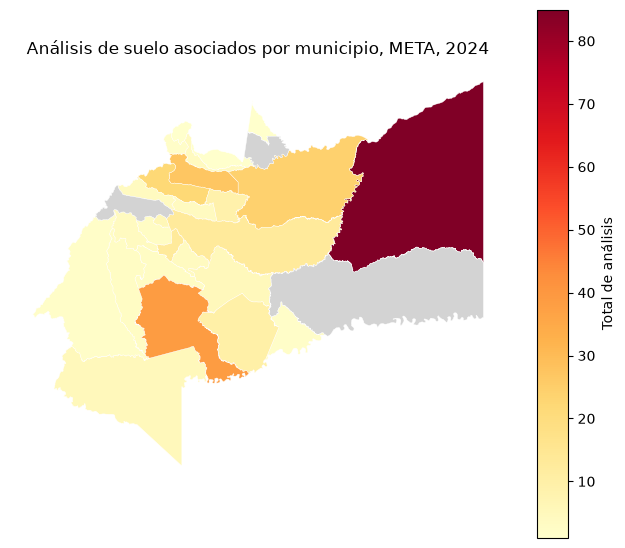

Mapa guardado en:  /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04


In [21]:
# Desarrollo
asociados = union_despues.loc[union_despues["estado_union"].eq("coincide")].copy()
print(asociados["anio"].value_counts().sort_index())

anio_elegido = 2024

asoc_anio = asociados.loc[asociados["anio"].eq(anio_elegido)].copy()
asoc_anio["ph_para_media"] = asoc_anio["ph"].where(asoc_anio["ph_valido"])

resumen_anual = (
    asoc_anio
    .groupby("codigo_municipio", as_index=False)
    .agg(
        total_analisis=("id_fila", "size"),
        ph_validos=("ph_valido", "sum"),
        ph_media=("ph_para_media", "mean"),
    )
)
resumen_anual["anio"] = anio_elegido

print(resumen_anual.shape, "| análisis:", resumen_anual["total_analisis"].sum())
print("Código único en resumen:", resumen_anual["codigo_municipio"].is_unique)
display(resumen_anual.sort_values("total_analisis", ascending=False).head())

municipios_validos["codigo_municipio"] = municipios_validos["mpio_cdpmp"].str.strip()

print("Capa: cinco cifras:", municipios_validos["codigo_municipio"].str.fullmatch(r"[0-9]{5}").all(),
      "| única:", municipios_validos["codigo_municipio"].is_unique)
print("Resumen: cinco cifras:", resumen_anual["codigo_municipio"].str.fullmatch(r"[0-9]{5}").all(),
      "| única:", resumen_anual["codigo_municipio"].is_unique)

poligonos_antes = len(municipios_validos)

mapa_municipal = municipios_validos.merge(
    resumen_anual,
    on="codigo_municipio",
    how="left",
    validate="one_to_one",
    indicator=True,
)

print(type(mapa_municipal).__name__, "| CRS:", mapa_municipal.crs, "| geometría activa:", mapa_municipal.geometry.name)
print(mapa_municipal["_merge"].value_counts())
assert len(mapa_municipal) == poligonos_antes

sin_resumen = mapa_municipal.loc[mapa_municipal["_merge"].eq("left_only"), ["codigo_municipio", "dpto_cnmbr", "mpio_cnmbr"]]
print("Municipios sin resumen:", len(sin_resumen))

sin_geometria = resumen_anual.loc[~resumen_anual["codigo_municipio"].isin(municipios_validos["codigo_municipio"])]
print("Códigos del resumen sin geometría:", len(sin_geometria), "| análisis afectados:", sin_geometria["total_analisis"].sum())
display(sin_geometria)

con_resumen = mapa_municipal["_merge"].eq("both").sum()
assert con_resumen + len(sin_geometria) == len(resumen_anual)
assert mapa_municipal["total_analisis"].sum() + sin_geometria["total_analisis"].sum() == resumen_anual["total_analisis"].sum()
print("Polígonos:", len(mapa_municipal), "| con resumen:", con_resumen, "| sin geometría:", len(sin_geometria))

mapa_9377 = mapa_municipal.copy().to_crs(epsg=9377)
mapa_9377["area_ha"] = mapa_9377.geometry.area / 10000

print("CRS:", mapa_9377.crs)
display(mapa_9377[["mpio_cnmbr", "mpio_narea", "area_ha"]].head())

display(mapa_municipal.groupby("dpto_cnmbr")["total_analisis"].sum().sort_values(ascending=False).head(8))

depto = "META"
mapa_depto = mapa_municipal.loc[mapa_municipal["dpto_cnmbr"].eq(depto)].copy()

fig, ax = plt.subplots(figsize=(8, 8))
mapa_depto.plot(
    column="total_analisis",
    cmap="YlOrRd",
    legend=True,
    legend_kwds={"label": "Total de análisis"},
    missing_kwds={"color": "lightgrey", "edgecolor": "white", "label": "Sin análisis en el resumen"},
    edgecolor="white",
    linewidth=0.3,
    ax=ax,
)
ax.set_title(f"Análisis de suelo asociados por municipio, {depto}, {anio_elegido}")
ax.set_axis_off()
plt.savefig(OUT + "/mapa_analisis.png", dpi=150, bbox_inches="tight")
plt.show()

from pathlib import Path
assert (Path(OUT) / "mapa_analisis.png").is_file()
print("Mapa guardado en: ", OUT)

**Interpretación:**

Se eligió **2024**, año presente en AGROSAVIA con 3.632 análisis asociados, y se resumieron en **503 municipios** con total, pH válidos y media de pH válido. Las claves tienen cinco cifras y son únicas en ambos lados, y el merge `one_to_one` desde `municipios_validos` conservó los **1.122** polígonos: **503** con resumen y **619** sin resumen. Ningún código del resumen quedó sin geometría, así que los 3.632 análisis están representados. La geometría activa y el CRS se conservaron.

**Área.** Se transformó una copia a EPSG:9377 y se calculó `area_ha = geometry.area / 10000`. No se calcula en grados porque en EPSG:4326 la unidad es el grado, cuya longitud en metros cambia con la latitud; `geometry.area` daría grados cuadrados, que no equivalen a hectáreas con un factor fijo. EPSG:9377 usa metros, y los resultados concuerdan con `mpio_narea` (por ejemplo, Medellín: 374,74 km² frente a 37.474 ha).

**Mapa.** Se mapeó **META** con el total de análisis por municipio. Puerto Gaitán concentra el valor más alto, y los municipios en gris no tienen análisis en el resumen de 2024.

**Diferencia DIVIPOLA 2024 y MGN 2025.** El catálogo territorial es un corte de 2024 y los polígonos son del MGN 2025. Los códigos coincidieron en los 1.122 casos y el merge no dejó huérfanos, pero eso no garantiza que los límites sean los mismos entre ambos cortes.

**Límites.**
- Un municipio gris significa que no hay análisis de 2024 en esta fuente.
- La media de pH describe los análisis disponibles, y con pocos análisis por municipio es poco estable.
- El mapa muestra dónde se pidió análisis de suelo.

## 8. Intersección espacial con la muestra IGAC · 30 minutos

Proyecta copias de `municipios_validos` y `capacidad_valida` a EPSG:9377. Conserva una columna que identifique cada polígono IGAC a partir de su fila original. Selecciona solo códigos, identificador, atributos IGAC necesarios y geometría; evita nombres de columnas duplicados.

Ejecuta directamente `gpd.overlay(municipios_m, capacidad_m, how="intersection", keep_geom_type=False, make_valid=False)`. `make_valid=False` exige que hayas resuelto la validez de forma visible. Inspecciona los tipos resultantes, registra contactos de área cero y conserva las piezas poligonales de área positiva en `intersecciones`. Calcula hectáreas a partir de la geometría de cada pieza, no del atributo de área original.

Resume el área intersectada por municipio como `area_intersectada_ha` e intégrala a `mapa_municipal` con `validate="one_to_one"`. Para comparar geometrías originales y piezas, muestra un mapa de la extensión de la muestra y guárdalo como `mapa_interseccion.png`. No sumes áreas como cobertura única si hay solapamientos: diagnostica ese riesgo y explica el significado de la suma.

**Control:** presenta cantidad y área de piezas. Contrasta por polígono IGAC el área original y la suma intersectada, con tolerancia explícita y sin exigir igualdad si parte queda fuera de los municipios. Cinco polígonos son una muestra: no permiten estimar la capacidad de uso de un municipio completo. Esta intersección tampoco asigna una clase IGAC a una muestra individual AGROSAVIA.

EPSG:9377 EPSG:9377
Inválidas DANE: 0 | IGAC: 0
['codigo_municipio', 'dpto_cnmbr', 'mpio_cnmbr', 'geometry'] ['id_igac', 'OBJECTID', 'UCCapacida', 'Descripcio', 'geometry']
Resultado bruto: 9
Polygon         5
MultiPolygon    4
Name: count, dtype: int64
Contactos de área cero o no poligonales: 0
Series([], Name: count, dtype: int64)
Piezas poligonales con área positiva: 9
Área total de piezas (ha): 4545.23


,codigo_municipio,mpio_cnmbr,id_igac,UCCapacida,area_ha
0,11001,"BOGOTÁ, D.C.",3,2c,874.791557
1,11001,"BOGOTÁ, D.C.",4,2c,422.606857
2,25099,BOJACÁ,2,2c,104.680216
3,25473,MOSQUERA,2,2c,89.257906
4,25473,MOSQUERA,3,2c,1.629363
5,25740,SIBATÉ,0,2c,1253.729650
6,25754,SOACHA,0,2c,344.167274
7,25754,SOACHA,1,2c,359.443210
8,25754,SOACHA,2,2c,1094.927501


  codigo_municipio  area_intersectada_ha
0            11001           1297.398414
1            25099            104.680216
2            25473             90.887269
3            25740           1253.729650
4            25754           1798.537985
5 municipios con intersección
Pares de polígonos IGAC que se solapan: 0
Área solapada (ha): 0.0


,id_igac,area_original_ha,area_intersectada_ha,piezas,diferencia_ha,dentro_tolerancia,intersectada_mayor_que_original
0,0,1597.896924,1597.896924,2,9.322321e-12,True,False
1,1,359.443210,359.443210,1,1.136868e-13,True,False
2,2,1288.865623,1288.865623,3,5.229595e-12,True,False
3,3,876.420920,876.420920,2,5.684342e-13,True,False
4,4,422.606857,422.606857,1,0.000000e+00,True,False


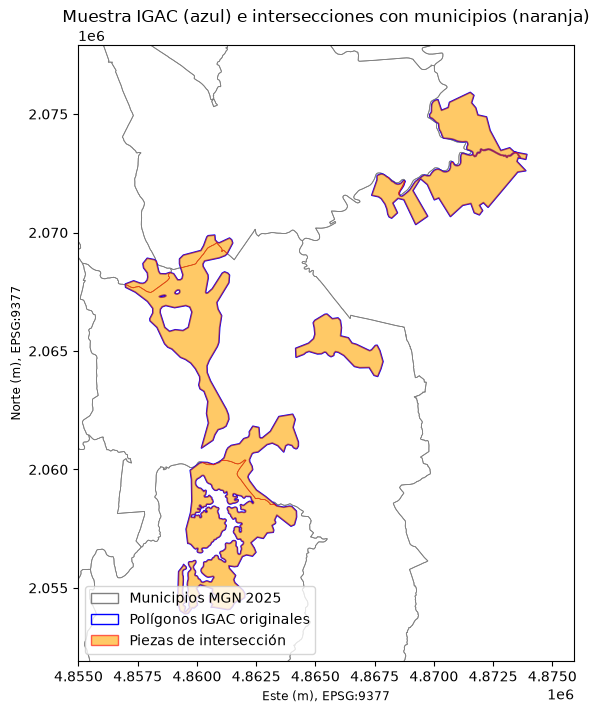

In [25]:
# Desarrollo
municipios_m = municipios_validos[["mpio_cdpmp", "dpto_cnmbr", "mpio_cnmbr", "geometry"]].copy()
municipios_m = municipios_m.rename(columns={"mpio_cdpmp": "codigo_municipio"}).to_crs(epsg=9377)

capacidad_m = capacidad_valida.copy()
capacidad_m["id_igac"] = capacidad_m.index
capacidad_m = capacidad_m[["id_igac", "OBJECTID", "UCCapacida", "Descripcio", "geometry"]].to_crs(epsg=9377)

print(municipios_m.crs, capacidad_m.crs)
print("Inválidas DANE:", (~municipios_m.is_valid).sum(), "| IGAC:", (~capacidad_m.is_valid).sum())
print(list(municipios_m.columns), list(capacidad_m.columns))

# Intersecta con overlay, calcula áreas de piezas y explica los límites de la integración espacial.
cruce = gpd.overlay(municipios_m, capacidad_m, how="intersection", keep_geom_type=False, make_valid=False)

print("Resultado bruto:", len(cruce))
print(cruce.geom_type.value_counts())

cruce["area_ha"] = cruce.geometry.area / 10000

es_poligono = cruce.geom_type.isin(["Polygon", "MultiPolygon"])
area_positiva = cruce["area_ha"] > 0

contactos = cruce.loc[~(es_poligono & area_positiva)]
intersecciones = cruce.loc[es_poligono & area_positiva].copy()

print("Contactos de área cero o no poligonales:", len(contactos))
print(contactos.geom_type.value_counts())
print("Piezas poligonales con área positiva:", len(intersecciones))
print("Área total de piezas (ha):", round(intersecciones["area_ha"].sum(), 2))
display(intersecciones[["codigo_municipio", "mpio_cnmbr", "id_igac", "UCCapacida", "area_ha"]])

area_por_municipio = (
    intersecciones
    .groupby("codigo_municipio", as_index=False)
    .agg(area_intersectada_ha=("area_ha", "sum"))
)
print(area_por_municipio)

filas_mapa = len(mapa_municipal)

mapa_municipal = mapa_municipal.drop(
    columns=["_merge", "area_intersectada_ha"], errors="ignore"
).merge(
    area_por_municipio,
    on="codigo_municipio",
    how="left",
    validate="one_to_one",
)

assert len(mapa_municipal) == filas_mapa
assert "area_intersectada_ha" in mapa_municipal.columns
assert isinstance(mapa_municipal, gpd.GeoDataFrame)
print(mapa_municipal["area_intersectada_ha"].notna().sum(), "municipios con intersección")

sol = gpd.overlay(
    capacidad_m[["id_igac", "geometry"]],
    capacidad_m[["id_igac", "geometry"]],
    how="intersection", keep_geom_type=True, make_valid=False,
)
sol = sol.loc[sol["id_igac_1"] < sol["id_igac_2"]].copy()
sol["area_ha"] = sol.geometry.area / 10000
print("Pares de polígonos IGAC que se solapan:", (sol["area_ha"] > 0).sum())
print("Área solapada (ha):", round(sol["area_ha"].sum(), 4))

tolerancia_ha = 0.01

area_igac = capacidad_m.assign(area_original_ha=capacidad_m.geometry.area / 10000)[["id_igac", "area_original_ha"]]
area_inter = intersecciones.groupby("id_igac", as_index=False).agg(area_intersectada_ha=("area_ha", "sum"), piezas=("area_ha", "size"))

control = area_igac.merge(area_inter, on="id_igac", how="left", validate="one_to_one")
control["area_intersectada_ha"] = control["area_intersectada_ha"].fillna(0)
control["diferencia_ha"] = control["area_original_ha"] - control["area_intersectada_ha"]
control["dentro_tolerancia"] = control["diferencia_ha"].abs() <= tolerancia_ha
control["intersectada_mayor_que_original"] = control["area_intersectada_ha"] > control["area_original_ha"] + tolerancia_ha
display(control)

assert not control["intersectada_mayor_que_original"].any()

minx, miny, maxx, maxy = capacidad_m.total_bounds
margen = 2000

fig, ax = plt.subplots(figsize=(8, 8))
municipios_m.plot(ax=ax, facecolor="none", edgecolor="grey", linewidth=0.6)
capacidad_m.plot(ax=ax, facecolor="none", edgecolor="blue", linewidth=1.2)
intersecciones.plot(ax=ax, color="orange", alpha=0.6, edgecolor="red", linewidth=0.4)
ax.set_xlim(minx - margen, maxx + margen)
ax.set_ylim(miny - margen, maxy + margen)
ax.set_title("Muestra IGAC (azul) e intersecciones con municipios (naranja)")
ax.set_xlabel("Este (m), EPSG:9377")
ax.set_ylabel("Norte (m), EPSG:9377")
ax.legend(handles=[
    Patch(facecolor="none", edgecolor="grey", label="Municipios MGN 2025"),
    Patch(facecolor="none", edgecolor="blue", label="Polígonos IGAC originales"),
    Patch(facecolor="orange", edgecolor="red", alpha=0.6, label="Piezas de intersección"),
], loc="lower left")
plt.savefig(OUT + "/mapa_interseccion.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:**

Se proyectaron copias de `municipios_validos` y `capacidad_valida` a EPSG:9377 y se identificó cada polígono IGAC con `id_igac`, tomado de su fila original. Ambas capas tenían 0 geometrías inválidas, por lo que `gpd.overlay(..., make_valid=False)` se ejecutó sin reparaciones ocultas.

**Piezas.** El cruce produjo **9** resultados (5 `Polygon` y 4 `MultiPolygon`). No hubo contactos de área cero ni geometrías no poligonales, así que las 9 piezas quedaron en `intersecciones`, con un área total de **4.545,23 ha** calculada a partir de la geometría de cada pieza, no del atributo de área de IGAC. Intersectan **5 municipios**: Bogotá D.C. (1.297,40 ha), Soacha (1.798,54 ha), Sibaté (1.253,73 ha), Mosquera (90,89 ha) y Bojacá (104,68 ha). Ese resumen (`area_intersectada_ha`) se integró a `mapa_municipal` con `validate="one_to_one"`; los demás municipios quedan con valor ausente y no con cero.

**Control por polígono IGAC.** Con tolerancia explícita de 0,01 ha, el área original coincide con la suma de sus piezas en los cinco polígonos (diferencias del orden de 1e-12 ha). Es decir, cada polígono de la muestra queda completamente dentro de los municipios del MGN 2025; si parte hubiera quedado fuera, la diferencia sería positiva y no se habría exigido igualdad.

**Solapamientos.** Se comparó cada polígono IGAC con los demás: **0 pares** se solapan y el área solapada es 0 ha. Por eso la suma de 4.545,23 ha equivale al área ocupada por la muestra, sin contar dos veces ninguna zona. Si hubiera solapamientos, esa suma sería una suma de áreas de polígonos y no una cobertura única.

**Merge frente a overlay.** El merge por código unió atributos sin mirar la forma de las geometrías. El overlay usó posición y forma para partir los polígonos IGAC según los límites municipales. `mapa_interseccion.png` muestra los polígonos originales, los límites municipales y las piezas.

**Límites.**
- Son solo cinco polígonos, en una zona pequeña de Cundinamarca y Bogotá. No permiten estimar la capacidad de uso de un municipio completo: las 1.297 ha de Bogotá son una fracción mínima de su territorio.
- Todas las piezas son de clase `2c`, así que la muestra no representa la variedad de clases de capacidad de uso.
- La intersección no asigna una clase IGAC a ninguna muestra individual de AGROSAVIA, porque estas no tienen ubicación propia.

## 9. Publicación y relectura · 35 minutos

Guarda `analisis_integrados.parquet` en OUT con `to_parquet(engine="pyarrow", compression="snappy", index=False)`. Incluye todas las filas, columnas originales, tipos definidos en el contrato, indicadores y procedencia. Usa nombres inequívocos para las coordenadas territoriales. Conserva `codigo_departamento` y `codigo_municipio` como texto; los códigos no resueltos permanecen ausentes.

Vuelve a leer mediante `pd.read_parquet(OUT + "/analisis_integrados.parquet", engine="pyarrow")`. Compara contenido ordenado por `id_fila`, tipos y cantidad de filas. Exporta a CSV controles, equivalencias, resumen y registros pendientes, sin índice. Escribe el contrato en una celda Markdown.

**Control:** reinicia el kernel y reejecuta; la salida debe conservar el mismo contenido. Las escrituras reemplazan archivos concretos de OUT. No modifiques los CSV originales.

Exporta `mapa_municipal` e `intersecciones` como capas separadas con llamadas explícitas:

```python
mapa_municipal.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="municipios",
    driver="GPKG", engine="pyogrio", index=False
)
intersecciones.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="intersecciones",
    driver="GPKG", engine="pyogrio", index=False
)
```
 Convierte explícitamente a texto las columnas categóricas, como el indicador del merge, antes de exportar si el controlador lo requiere. En cada reejecución crea un GeoPackage nuevo o reemplaza solo las capas indicadas; no uses append.

Relee cada capa con `gpd.read_file(OUT + "/resultados_espaciales.gpkg", layer="municipios", engine="pyogrio")` y la llamada equivalente para intersecciones. Verifica filas, claves, CRS, geometría activa, valores y áreas con tolerancia. Los tipos restaurados por GeoPackage pueden variar: documenta las diferencias. El Parquet tabular que usa PD05 conserva todas las observaciones y no lleva la geometría municipal repetida en cada análisis.


In [26]:
# Desarrollo
analisis_integrados = union_despues.copy()

# El indicador del merge es categórico: se pasa a texto con otro nombre
analisis_integrados["merge_indicador"] = analisis_integrados["_merge"].astype("string")
analisis_integrados = analisis_integrados.drop(columns=["_merge"])

# Códigos, nombres y claves como texto; los no resueltos quedan como <NA>
columnas_texto = [
    "codigo_departamento", "codigo_municipio", "departamento", "municipio",
    "estado_union", "clave_depto", "clave_mpio", "clave_union",
    "clave_union_eq", "clave_compuesta",
]
for c in columnas_texto:
    analisis_integrados[c] = analisis_integrados[c].astype("string")

# Procedencia
analisis_integrados["fuente_analisis"] = "agrosavia.csv"
analisis_integrados["fuente_territorial"] = "divipola.csv (corte 2024)"

print(analisis_integrados.shape)
print(analisis_integrados[["id_fila", "fecha_dt", "anio", "ph", "ph_valido",
                           "codigo_departamento", "codigo_municipio",
                           "longitud_territorial", "latitud_territorial",
                           "estado_union"]].dtypes)
print(analisis_integrados[["codigo_departamento", "codigo_municipio"]].isna().sum())

assert len(analisis_integrados) == filas_suelo
assert analisis_integrados["id_fila"].is_unique

ruta_parquet = OUT + "/analisis_integrados.parquet"
analisis_integrados.to_parquet(ruta_parquet, engine="pyarrow", compression="snappy", index=False)
print("Escrito:", ruta_parquet)


leido = pd.read_parquet(ruta_parquet, engine="pyarrow")

a = analisis_integrados.sort_values("id_fila").reset_index(drop=True)
b = leido.sort_values("id_fila").reset_index(drop=True)

print("Filas:", len(a), "|", len(b))
print("Tipos iguales:", a.dtypes.equals(b.dtypes))

pd.testing.assert_frame_equal(a, b)
print("Contenido, tipos y filas idénticos tras releer")

controles = pd.DataFrame({
    "control": [
        "Total de entrada",
        "pH no válido",
        "Análisis asociados",
        "Análisis no asociados",
        "Filas con equivalencia aplicada",
        "Municipios en el resumen",
        "Polígonos DANE válidos",
        "Polígonos IGAC válidos",
    ],
    "cantidad": [
        filas_suelo,
        int((~analisis_integrados["ph_valido"]).sum()),
        len(asociados_total := analisis_integrados.loc[analisis_integrados["estado_union"].eq("coincide")]),
        len(no_asociados),
        int(analisis_integrados["equivalencia_aplicada"].sum()),
        len(resumen_municipal),
        len(municipios_validos),
        len(capacidad_valida),
    ],
})
display(controles)

pendientes = no_asociados[["id_fila", "Departamento", "Municipio", "clave_depto", "clave_mpio", "estado_union"]]

controles.to_csv(OUT + "/controles_pd04.csv", index=False)
equivalencias.to_csv(OUT + "/equivalencias.csv", index=False)
resumen_municipal.to_csv(OUT + "/resumen_municipal.csv", index=False)
pendientes.to_csv(OUT + "/registros_pendientes.csv", index=False)

print("Pendientes:", len(pendientes))

mapa_export = mapa_municipal.copy()
for c in mapa_export.select_dtypes(include="category").columns:
    mapa_export[c] = mapa_export[c].astype("string")

mapa_export.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="municipios",
    driver="GPKG", engine="pyogrio", index=False
)
intersecciones.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="intersecciones",
    driver="GPKG", engine="pyogrio", index=False
)

mapa_export = mapa_municipal.copy()
for c in mapa_export.select_dtypes(include="category").columns:
    mapa_export[c] = mapa_export[c].astype("string")

mapa_export.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="municipios",
    driver="GPKG", engine="pyogrio", index=False
)
intersecciones.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="intersecciones",
    driver="GPKG", engine="pyogrio", index=False
)

mun_leido = gpd.read_file(OUT + "/resultados_espaciales.gpkg", layer="municipios", engine="pyogrio")

assert len(mun_leido) == len(mapa_municipal)
assert mun_leido["codigo_municipio"].is_unique
assert set(mun_leido["codigo_municipio"]) == set(mapa_municipal["codigo_municipio"])
assert mun_leido.crs == mapa_municipal.crs
assert mun_leido.geometry.name == "geometry"

cols = [c for c in mapa_export.columns if c != "geometry"]
a = mapa_export.sort_values("codigo_municipio").reset_index(drop=True)[cols]
b = mun_leido.sort_values("codigo_municipio").reset_index(drop=True)[cols]
pd.testing.assert_frame_equal(a, b, check_dtype=False)

area_orig = mapa_municipal.set_index("codigo_municipio").to_crs(epsg=9377).geometry.area / 10000
area_leida = mun_leido.set_index("codigo_municipio").to_crs(epsg=9377).geometry.area / 10000
dif = (area_orig - area_leida.reindex(area_orig.index)).abs().max()
print("Diferencia máxima de área (ha):", dif)
assert dif < 0.01

print(mapa_municipal.geom_type.value_counts())
print(mun_leido.geom_type.value_counts())
print(pd.DataFrame({"antes": a.dtypes, "despues": b.dtypes})[a.dtypes.ne(b.dtypes)])

int_leido = gpd.read_file(OUT + "/resultados_espaciales.gpkg", layer="intersecciones", engine="pyogrio")

clave = ["codigo_municipio", "id_igac"]
a = intersecciones.sort_values(clave).reset_index(drop=True)
b = int_leido.sort_values(clave).reset_index(drop=True)

assert len(a) == len(b) == 9
assert a.crs == b.crs
assert b.geometry.name == "geometry"

cols = [c for c in a.columns if c != "geometry"]
pd.testing.assert_frame_equal(a[cols], b[cols], check_dtype=False)

dif_area = (a.geometry.area / 10000 - b.geometry.area / 10000).abs().max()
print("Diferencia máxima de área (ha):", dif_area)
assert dif_area < 0.01

print(b.crs)
print(pd.DataFrame({"antes": a[cols].dtypes, "despues": b[cols].dtypes})[a[cols].dtypes.ne(b[cols].dtypes)])

(92738, 54)
id_fila                          Int64
fecha_dt                datetime64[ns]
anio                             Int64
ph                             float64
ph_valido                         bool
codigo_departamento     string[python]
codigo_municipio        string[python]
longitud_territorial           float64
latitud_territorial            float64
estado_union            string[python]
dtype: object
codigo_departamento    177
codigo_municipio       177
dtype: int64
Escrito: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04/analisis_integrados.parquet
Filas: 92738 | 92738
Tipos iguales: True
Contenido, tipos y filas idénticos tras releer


,control,cantidad
0,Total de entrada,92738
1,pH no válido,11
2,Análisis asociados,92561
3,Análisis no asociados,177
4,Filas con equivalencia aplicada,1961
5,Municipios en el resumen,1044
6,Polígonos DANE válidos,1122
7,Polígonos IGAC válidos,5


Pendientes: 177
Diferencia máxima de área (ha): 0.0
Polygon         1113
MultiPolygon       9
Name: count, dtype: int64
MultiPolygon    1122
Name: count, dtype: int64
                antes  despues
total_analisis  Int64  float64
Diferencia máxima de área (ha): 0.0
EPSG:9377
Empty DataFrame
Columns: [antes, despues]
Index: []


**Contrato de salida: `analisis_integrados.parquet`**

Una fila por análisis (92.738), con `id_fila` igual a la posición de la fila en el CSV. No lleva geometría. Los polígonos están en `resultados_espaciales.gpkg`.

| Campo | Tipo | Regla de validez | Tratamiento de ausencias |
|---|---|---|---|
| 32 columnas originales de AGROSAVIA | texto | Sin cambios | Vacíos y marcadores se conservan como texto |
| `id_fila` | Int64 | Entero único | No admite ausencias |
| `fecha_dt` | datetime64 | Formato `%d/%m/%Y` | `NaT` si no se interpreta |
| `anio` | Int64 | Año de `fecha_dt` | `<NA>` si `fecha_dt` es `NaT` |
| `ph` | float64 | Número con punto decimal | `NaN` si es vacío, censurado o erróneo; nunca 0 |
| `ph_valido` | bool | `ph` no ausente y en [0, 14] | `False` si `ph` es `NaN` |
| `codigo_departamento` | texto | Dos cifras | `<NA>` si la fila no se asocia |
| `codigo_municipio` | texto | Cinco cifras | `<NA>` si la fila no se asocia |
| `departamento`, `municipio` | texto | Nombre DIVIPOLA | `<NA>` si no se asocia |
| `longitud_territorial`, `latitud_territorial` | float64 | Coordenadas del municipio en DIVIPOLA 2024 | `NaN` si no se asocia |
| `estado_union` | texto | `coincide`, `clave_incompleta`, `ambigua` o `sin_correspondencia` | Toda fila tiene un estado |
| `merge_indicador` | texto | `both` o `left_only` del merge | Toda fila tiene valor |
| `clave_depto`, `clave_mpio`, `clave_union`, `clave_union_eq`, `clave_compuesta` | texto | Claves normalizadas de unión | `<NA>` si la clave está incompleta |
| `clave_incompleta`, `equivalencia_aplicada` | bool | Indicadores de la unión | Sin ausencias |
| `fuente_analisis`, `fuente_territorial` | texto | Procedencia de cada parte | Sin ausencias |

**Interpretación:**

Se publicó `analisis_integrados.parquet` con `to_parquet(engine="pyarrow", compression="snappy", index=False)`: **92.738** filas, 54 columnas y sin geometría. `codigo_departamento` y `codigo_municipio` se conservaron como texto, con **177** ausentes que corresponden a los 175 análisis sin correspondencia y los 2 con clave incompleta; no se rellenaron. Las coordenadas se nombran `longitud_territorial` y `latitud_territorial` porque son del municipio en DIVIPOLA, no de la muestra.

**Relectura.** Con `pd.read_parquet`, ordenando ambos lados por `id_fila`, el número de filas, los tipos y el contenido son idénticos (`assert_frame_equal` pasó).

**CSV exportados**: controles, equivalencias, resumen municipal y 177 registros pendientes. Los CSV originales de `RAW` no se modificaron.

**GeoPackage.** [Completar: filas, claves, CRS, geometría activa y diferencia máxima de área de las capas `municipios` (1.122) e `intersecciones` (9), y las diferencias de tipos observadas.]

**Límites.**
- El Parquet no incluye geometría: la unión con los polígonos se hace por `codigo_municipio`.
- Los 177 análisis no asociados siguen sin territorio y no entran al resumen ni al mapa.

## Entrega

`soluciones/PD04_limpieza_integracion_territorial.ipynb`, con contrato, código visible, controles y tres conclusiones. Los resultados regenerables se guardan en `kit/salidas/soluciones/PD04/`. PD05 utiliza `analisis_integrados.parquet`; no elimines registros para facilitar esa actividad.

Incluye también los dos mapas PNG, el GeoPackage con municipios e intersecciones, el control de CRS y geometrías y la conciliación entre resumen tabular y mapa. PD05 reutiliza el Parquet de análisis y la capa municipal. Apoyo: [guía GeoPandas](../docs/manual-geopandas.md), [uniones de atributos y espaciales](https://geopandas.org/en/stable/docs/user_guide/mergingdata.html).
